# Imports

In [1]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

In [2]:
def show_rgb(img, title="Image"):
    if img.ndim == 3:
        img = cv.cvtColor(img, cv.COLOR_BGR2RGB)

    plt.figure(figsize=(6, 4))
    plt.imshow(img, cmap='gray' if img.ndim == 2 else None)
    plt.title(title)
    plt.axis('off')
    plt.show()

# Question 1

In [3]:
def intensity_transform(im, breakpoints):
    """
    Apply piecewise-linear intensity transformation.

    breakpoints:
        Nx2 array
        first column  = input intensity
        second column = output intensity
    """

    breakpoints = np.asarray(breakpoints, dtype=np.float32)

    x = breakpoints[:, 0]
    y = breakpoints[:, 1]

    transformed = np.interp(im.astype(np.float32), x, y)

    return np.clip(transformed, 0, 255).astype(np.uint8)

In [4]:
def plot_transformed(img, breakpoints, label=None):
    """
    Plot the original and transformed images along with the transformation function.
    """

    transformed = intensity_transform(img, breakpoints)

    plt.figure(figsize=(12, 4))

    plt.subplot(1, 3, 1)
    plt.imshow(img, cmap='gray')
    plt.title("Original Image")
    plt.axis('off')

    plt.subplot(1, 3, 2)
    plt.imshow(transformed, cmap='gray')
    if label is not None:
        plt.title(f"{label}")
    else:
        plt.title("Transformed Image")
    plt.axis('off')

    plt.subplot(1, 3, 3)
    x = breakpoints[:, 0]
    y = breakpoints[:, 1]
    plt.plot(x, y, marker='o')
    plt.title("Transformation Function")
    plt.xlabel("Input Intensity")
    plt.ylabel("Output Intensity")
    plt.grid()

    plt.tight_layout()
    plt.show()

In [5]:
emma = cv.imread("Images/emma.jpg", cv.IMREAD_GRAYSCALE)



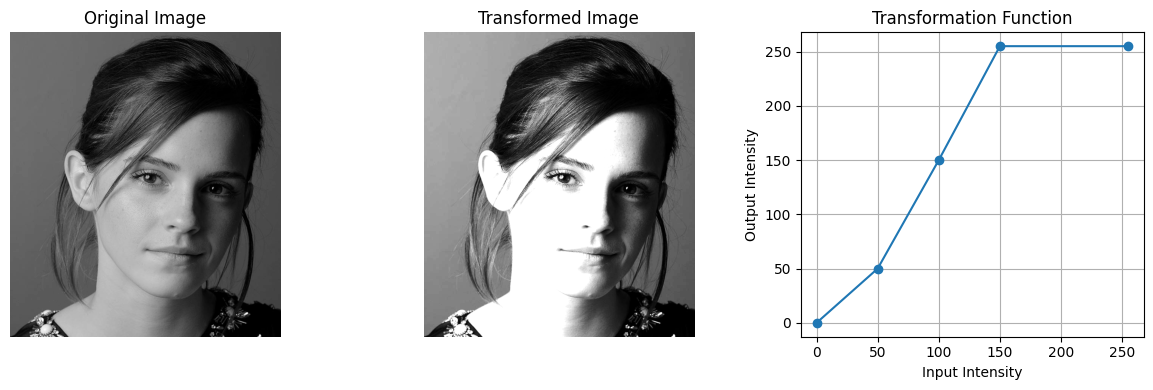

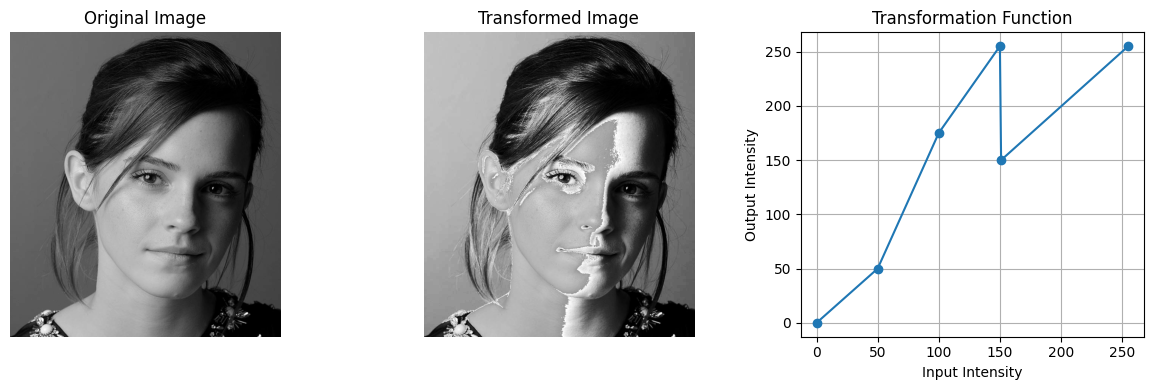

In [6]:
breakpoints1 = np.array([
    [0,   0],
    [50,  50],
    [100, 150],
    [150, 255],
    [255, 255]
])
breakpoints2 = np.array([
    [0, 0],
    [50,50],
    [100,175],
    [150,255],
    [151,150],
    [255,255]
])

plot_transformed(emma, breakpoints1)
plot_transformed(emma, breakpoints2)

# Question 2

[[ 1  1 10 ... 13 13  2]
 [ 1  1 10 ... 13 13  2]
 [ 1  1 10 ... 13 13  2]
 ...
 [ 9  9  8 ...  4  4  2]
 [ 9  9  8 ...  4  4  2]
 [ 9  9  8 ...  4  4  2]]


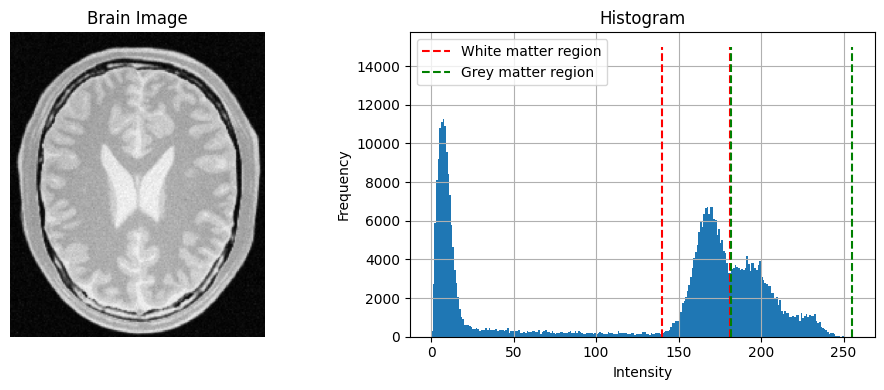

In [7]:
brain = cv.imread("Images/brain.png", cv.IMREAD_GRAYSCALE)
print(brain)
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(brain, cmap='gray')
plt.title("Brain Image")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.hist(brain.ravel(), bins=256, range=(0, 256))
plt.title("Histogram")
plt.xlabel("Intensity")
plt.ylabel("Frequency")
plt.grid(True)

ax1 = 140
plt.plot([ax1, ax1], [0, 15000], color='red', linestyle='--', label=f'White matter region')
ax2 = 181
plt.plot([ax2, ax2], [0, 15000], color='red', linestyle='--')
ax1 = 182
plt.plot([ax1, ax1], [0, 15000], color='green', linestyle='--', label=f'Grey matter region')
ax2 = 255
plt.plot([ax2, ax2], [0, 15000], color='green', linestyle='--')

plt.tight_layout()
plt.legend()
plt.show()

In [ ]:
breakpoints_grey = np.array([
    [0, 0],
    [140, 140*0.2],
    [150, 128],
    [168, 255],
    [175, 128],
    [182, 182*0.2],
    [255, 255*0.2]
])
breakpoints_white = np.array([
    [0, 0],
    [181, 181*0.2],
    [190, 200],
    [220, 255],
    [255, 255]
])

plot_transformed(brain, breakpoints_grey, label="Grey Matter Transformation")
plot_transformed(brain, breakpoints_white, label="White Matter Transformation")

## Grey matter accentuate

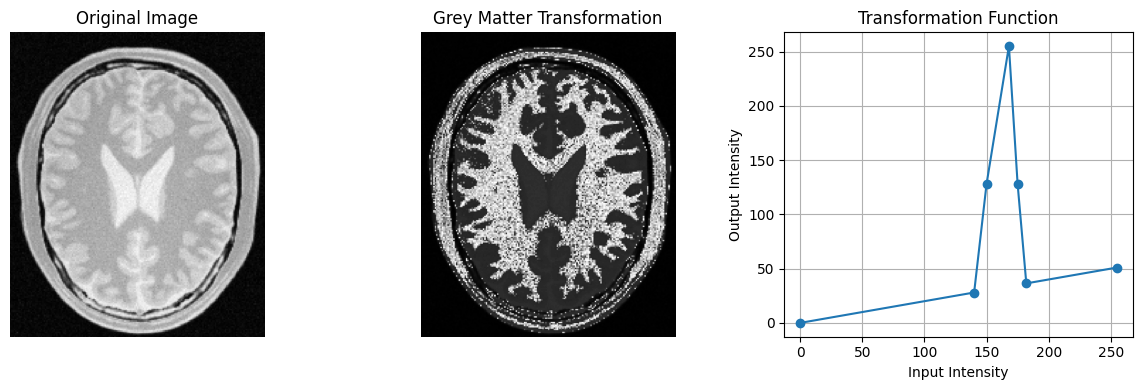

In [9]:
plot_transformed(brain, breakpoints_grey, label="Grey Matter Transformation")

## White matter accentuate

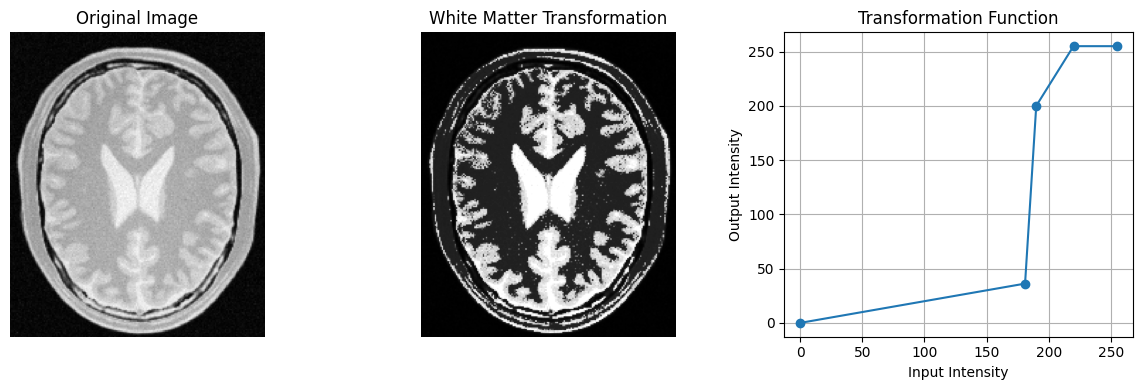

In [10]:

plot_transformed(brain, breakpoints_white, label="White Matter Transformation")

# Question 3

In [ ]:
img = cv.imread("Images/q3.png")

lab = cv.cvtColor(img, cv.COLOR_BGR2LAB)

L, a, b = cv.split(lab)

gamma = 1.5

L_norm = L.astype(np.float32) / 255.0
L_gamma = 255 * (L_norm ** gamma)
L_gamma = np.clip(L_gamma, 0, 255).astype(np.uint8)

lab_corrected = cv.merge([L_gamma, a, b])

corrected = cv.cvtColor(lab_corrected, cv.COLOR_LAB2RGB)

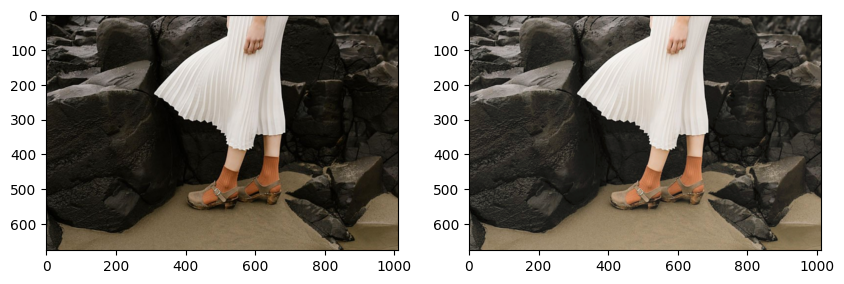

In [12]:
fig, ax = plt.subplots(1,2,figsize=(10, 5))
ax[0].imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
ax[1].imshow(corrected)

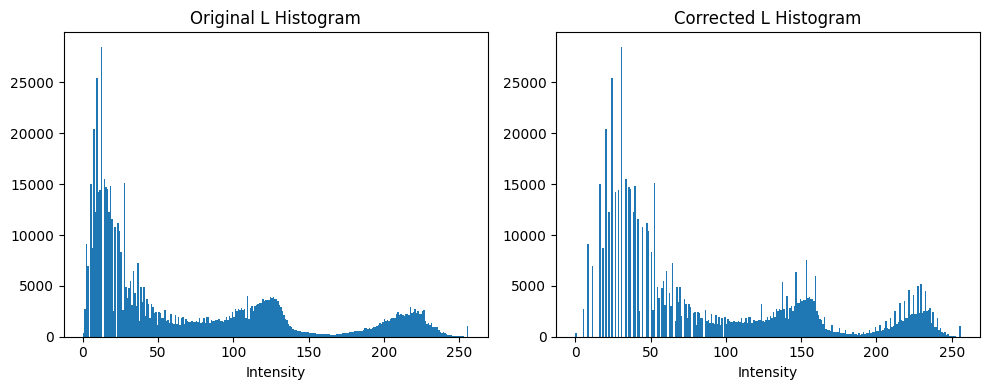

In [13]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.hist(L.ravel(), 256, [0,256])
plt.title("Original L Histogram")
plt.xlabel("Intensity")

plt.subplot(1, 2, 2)
plt.hist(L_gamma.ravel(), 256, [0,256])
plt.title("Corrected L Histogram")
plt.xlabel("Intensity")

plt.tight_layout()
plt.show()

# Question 4

## Part a

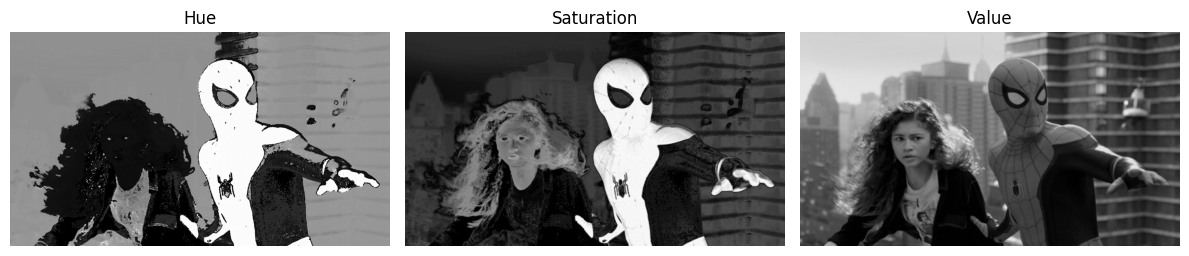

In [14]:
img = cv.imread("Images/spiderman.png")
hsv = cv.cvtColor(img, cv.COLOR_BGR2HSV)

H, S, V = cv.split(hsv)

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(H, cmap='gray')
plt.title("Hue")
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(S, cmap='gray')
plt.title("Saturation")
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(V, cmap='gray')
plt.title("Value")
plt.axis('off')

plt.tight_layout()
plt.show()

## Part b

In [15]:
def plot_vibrance_transformation(S, sigma=70, a_value=0.0):
    x = S.astype(np.float32)

    S_new = x + a_value * 128 * np.exp(
        -((x - 128)**2) / (2 * sigma**2)
    )

    S_new = np.clip(S_new, 0, 255).astype(np.uint8)

    # hsv_new = cv.merge([H, S_new, V])

    # vibrance = cv.cvtColor(hsv_new, cv.COLOR_HSV2BGR)

    x_plot = np.arange(256)

    y_plot = x_plot + a_value * 128 * np.exp(
        -((x_plot - 128)**2)/(2*sigma**2)
    )

    y_plot = np.clip(y_plot, 0, 255)

    plt.figure(figsize=(5, 5))
    plt.plot(x_plot, y_plot)
    plt.xlabel("Input Saturation")
    plt.ylabel("Output Saturation")
    plt.title(f"Vibrance Transformation, a={a_value}")
    plt.grid()
    plt.show()

    plt.figure(figsize=(10, 4))

    plt.subplot(1, 2, 1)
    plt.imshow(S, cmap='gray')
    plt.title("Original")
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.imshow(S_new, cmap='gray')
    plt.title(f"Vibrance Enhanced, a={a_value}")
    plt.axis('off')

    plt.tight_layout()
    plt.show()

    return S_new

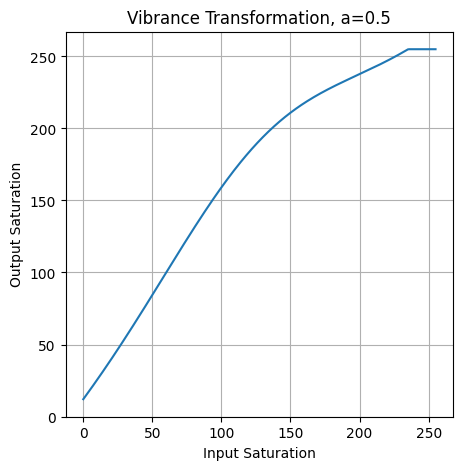

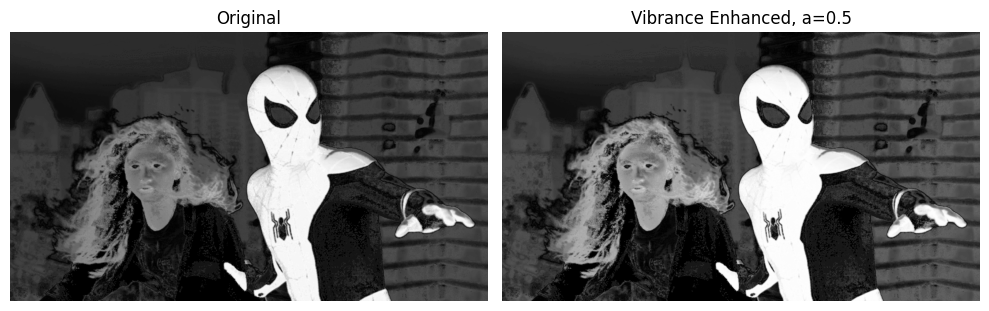

array([[12, 12, 12, ..., 12, 12, 12],
       [12, 12, 12, ..., 12, 12, 12],
       [51, 48, 48, ..., 52, 55, 59],
       ...,
       [43, 43, 49, ..., 96, 96, 90],
       [61, 61, 56, ..., 92, 92, 93],
       [56, 52, 52, ..., 93, 93, 93]], dtype=uint8)

In [16]:
plot_vibrance_transformation(S, sigma=70, a_value=0.5)

## Part C

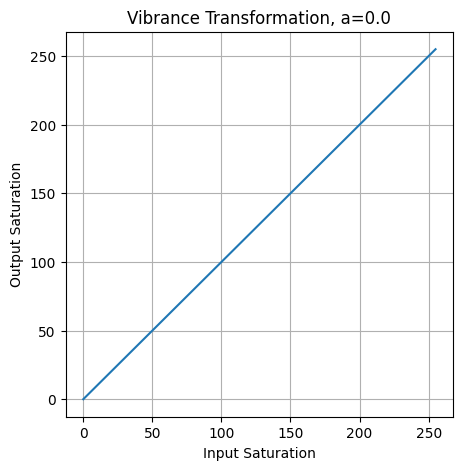

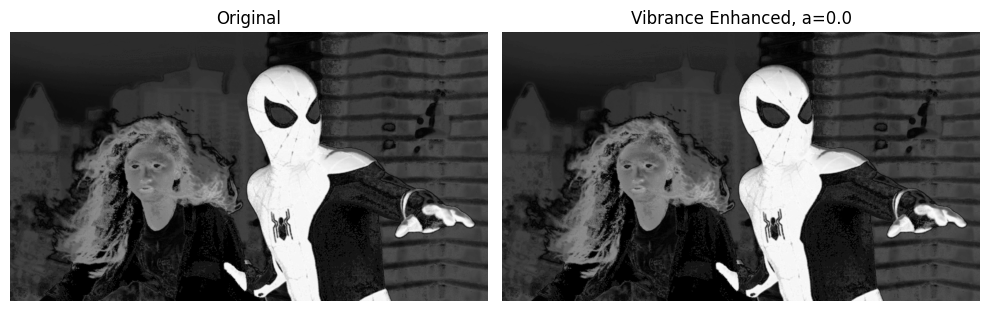

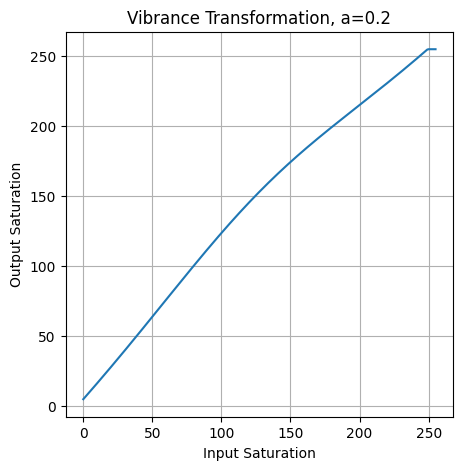

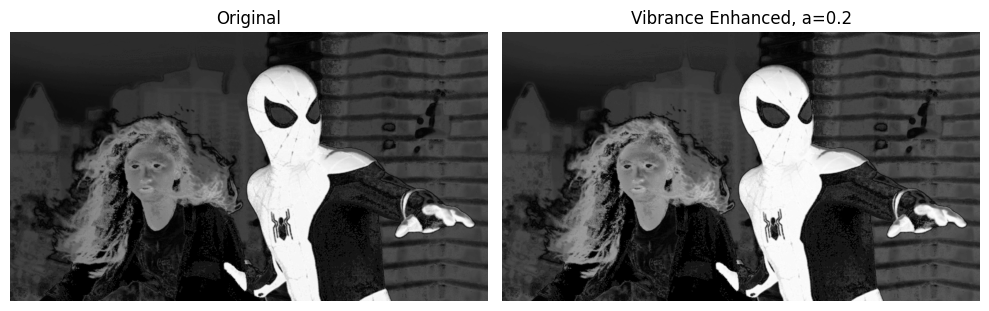

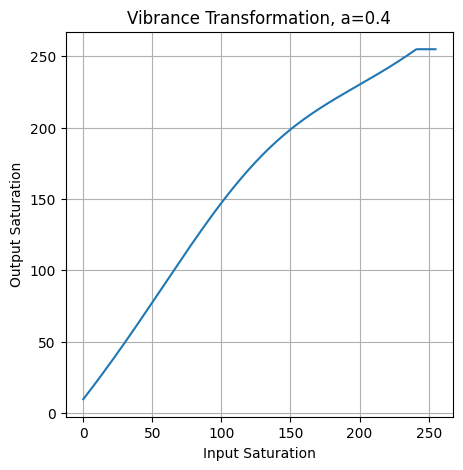

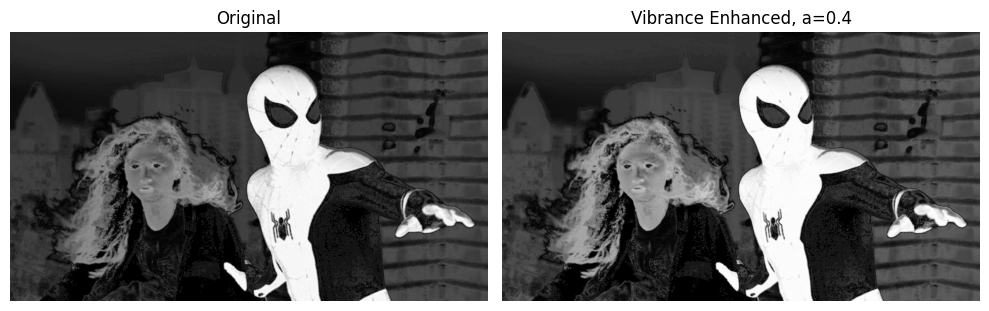

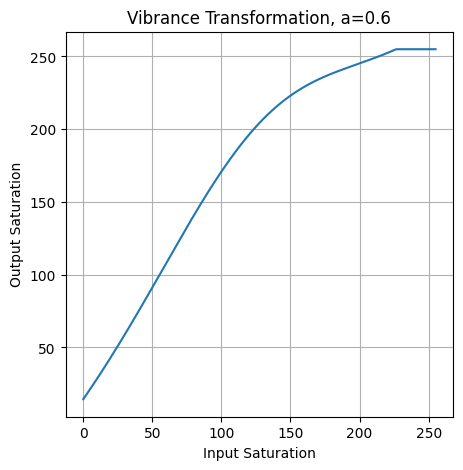

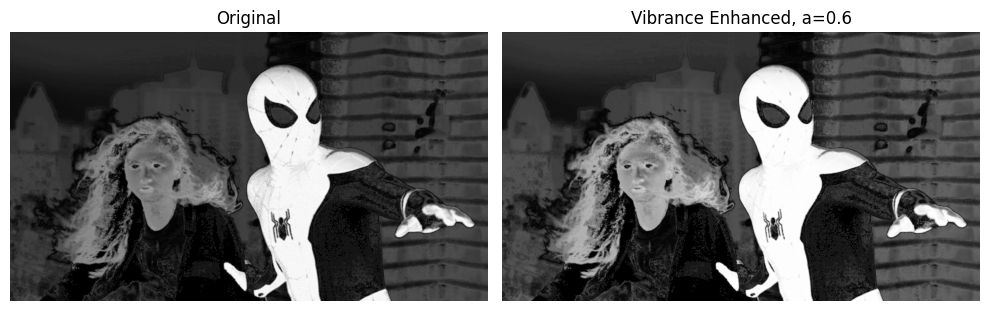

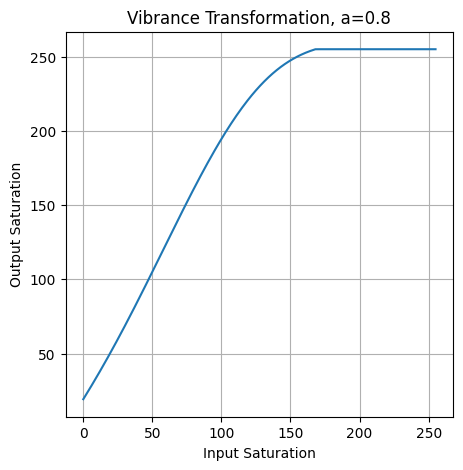

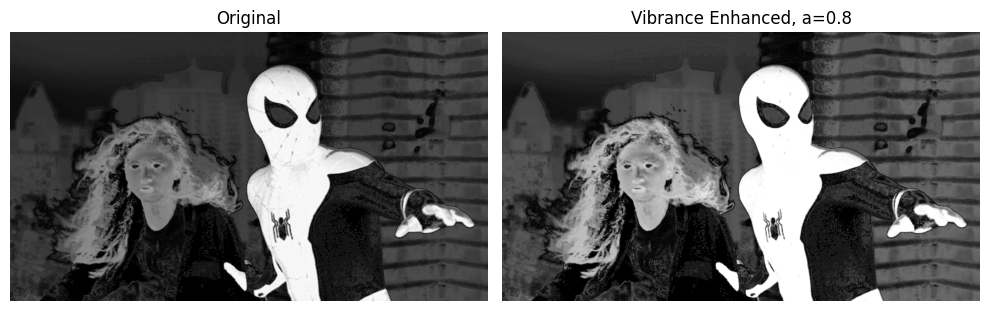

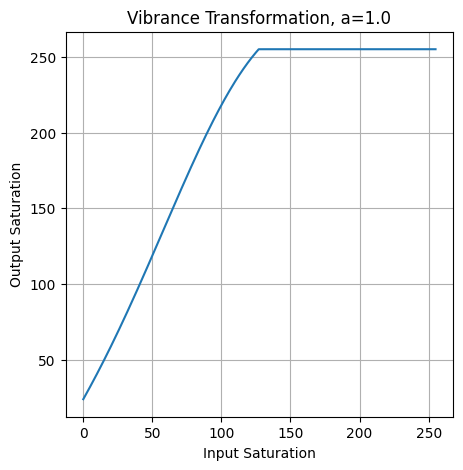

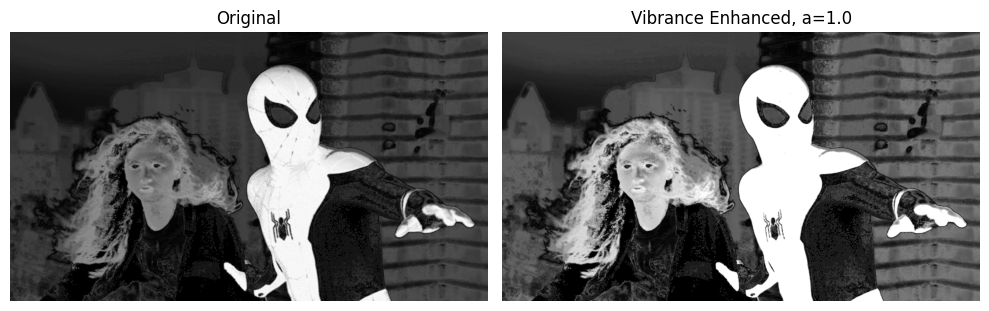

In [17]:
for a in range(0, 11, 2):
    plot_vibrance_transformation(S, sigma=70, a_value=a/10)

## Part d

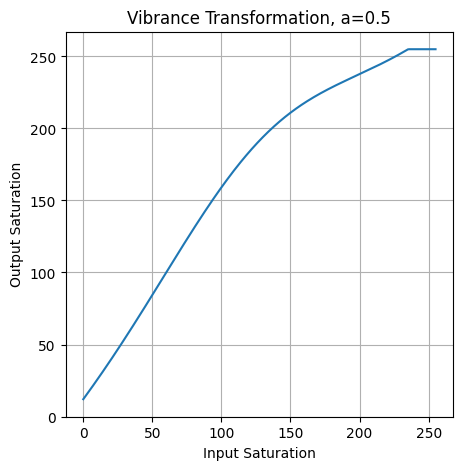

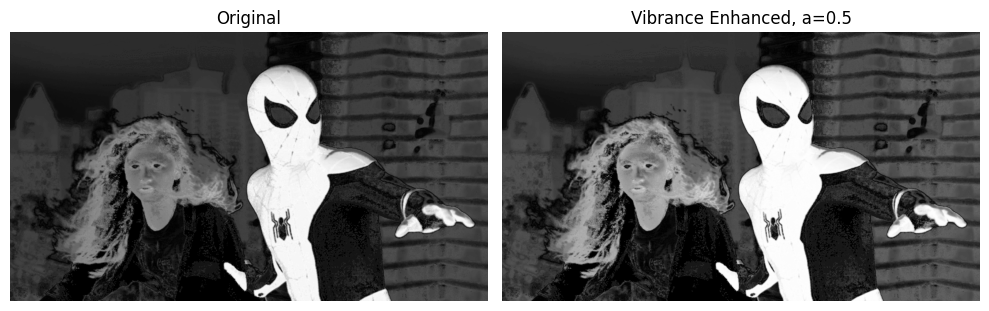

In [18]:
a_value = 0.5
modifiedImg = cv.merge([H, plot_vibrance_transformation(S, sigma=70, a_value=0.5), V])

## Part e

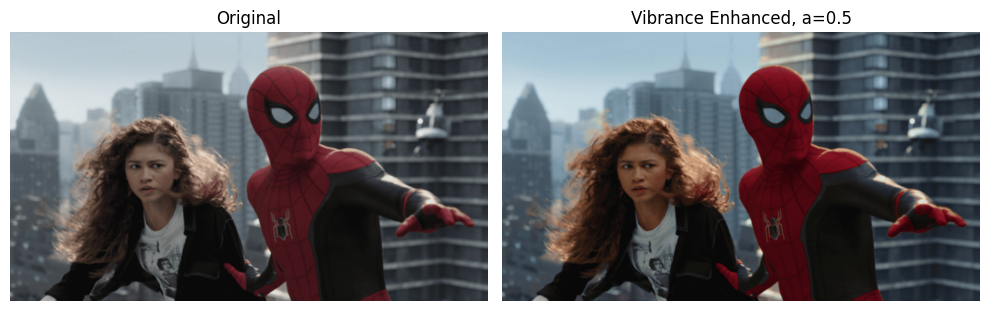

In [19]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
plt.title("Original")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(cv.cvtColor(modifiedImg, cv.COLOR_HSV2RGB))
plt.title(f"Vibrance Enhanced, a={a_value}")
plt.axis('off')

plt.tight_layout()
plt.show()




# Question 5

(-0.5, 881.5, 887.5, -0.5)

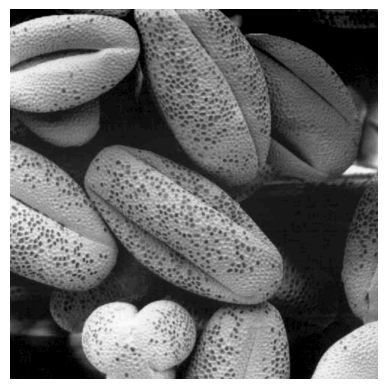

In [20]:
img = cv.imread("Images/q5.png", cv.IMREAD_GRAYSCALE)

plt.imshow(img, cmap="grey")
plt.axis("off")

Text(0.5, 1.0, 'Distribution')

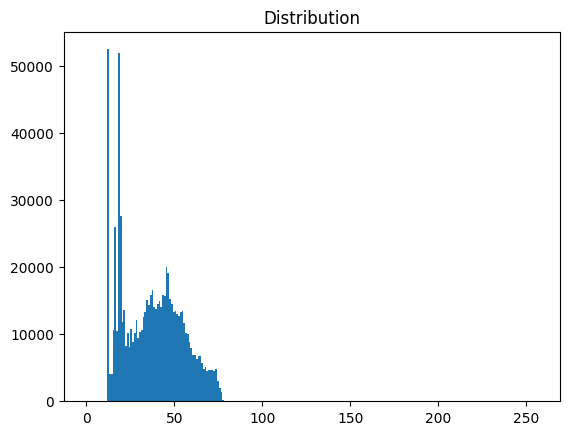

In [21]:
plt.hist(img.ravel(), bins=255, range=(0,256))
plt.title("Distribution")

In [22]:
def hist_equalization(img):

    hist = np.zeros(256)

    for pixel in img.ravel():
        hist[pixel] += 1

    pdf = hist / img.size

    cdf = np.cumsum(pdf)

    cdf_nonzero = cdf[cdf > 0]

    cdf_min = cdf_nonzero[0]

    mapping = np.round(
        (cdf - cdf_min) /
        (cdf[-1] - cdf_min) * 255
    )

    mapping = np.clip(mapping, 0, 255).astype(np.uint8)
    return mapping[img]

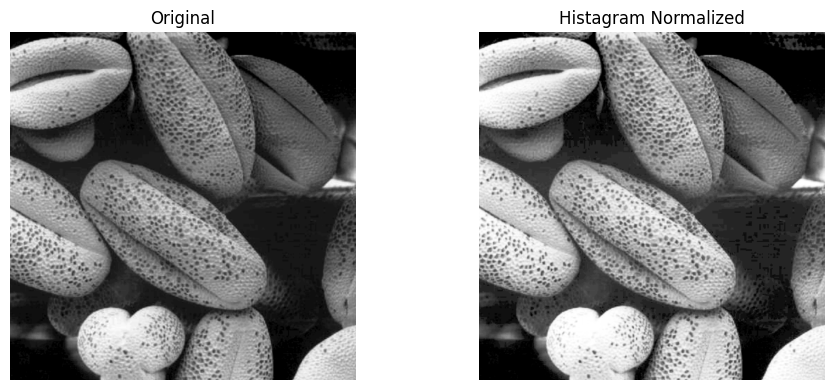

In [23]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap="grey")
plt.title("Original")
plt.axis('off')

hist_norm = hist_equalization(img)
plt.subplot(1, 2, 2)
plt.imshow(hist_norm, cmap="grey")
plt.title(f"Histagram Normalized")
plt.axis('off')

plt.tight_layout()
plt.show()


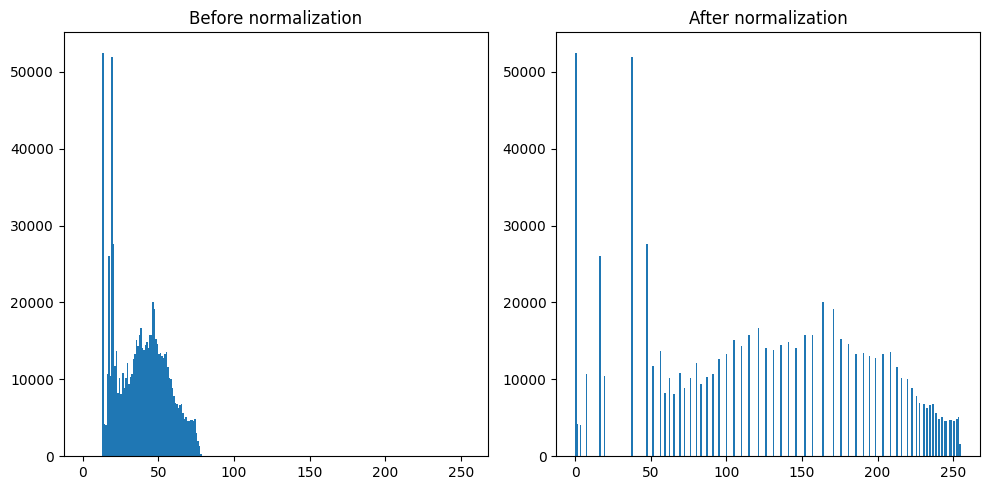

In [24]:
plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
plt.hist(img.ravel(), 256, (0,255))
plt.title("Before normalization")
plt.subplot(1,2,2)
plt.hist(hist_norm.ravel(), 256, (0,255))
plt.title("After normalization")

plt.tight_layout()
plt.show()

# Question 6

## Part a

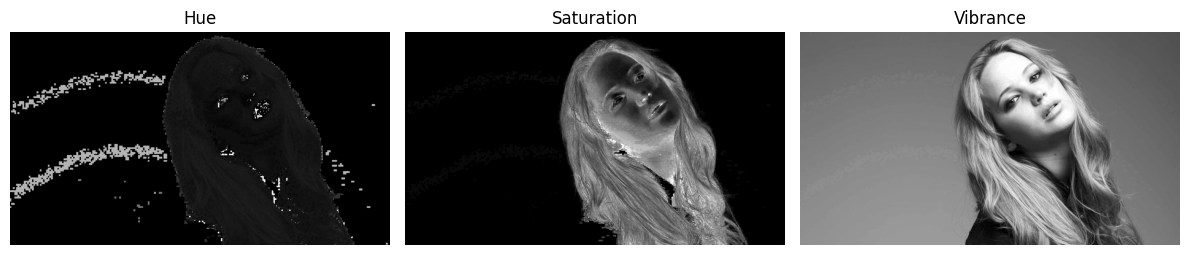

In [25]:
img = cv.imread("Images/q6.png", cv.IMREAD_COLOR_RGB)

H,S,V = cv.split(cv.cvtColor(img, cv.COLOR_RGB2HSV))

plt.figure(figsize=(12,6))
plt.subplot(1,3,1)
plt.imshow(H, cmap="grey")
plt.title("Hue")
plt.axis("off")
plt.subplot(1,3,2)
plt.imshow(S, cmap="grey")
plt.title("Saturation")
plt.axis("off")
plt.subplot(1,3,3)
plt.imshow(V, cmap="grey")
plt.title("Vibrance")
plt.axis("off")

plt.tight_layout()
plt.show()

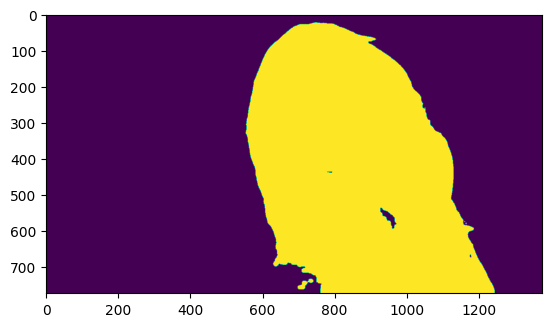

In [26]:
mask = np.array(cv.GaussianBlur(S, (11, 11), 20)>11, dtype=np.uint8)
plt.imshow(mask)

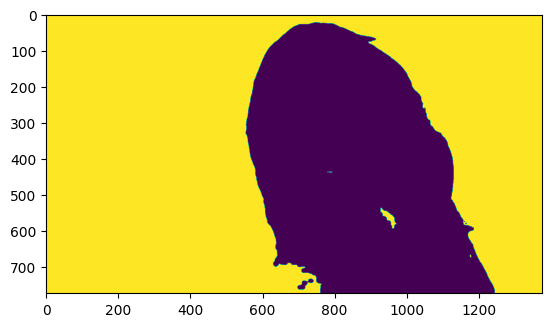

In [27]:
plt.imshow(cv.bitwise_not(mask))

In [28]:
cv.bitwise_not(mask)

array([[255, 255, 255, ..., 255, 255, 255],
       [255, 255, 255, ..., 255, 255, 255],
       [255, 255, 255, ..., 255, 255, 255],
       ...,
       [255, 255, 255, ..., 255, 255, 255],
       [255, 255, 255, ..., 255, 255, 255],
       [255, 255, 255, ..., 255, 255, 255]], dtype=uint8)

In [29]:
foreground = cv.bitwise_and(img,img, mask=mask)
background = img - foreground

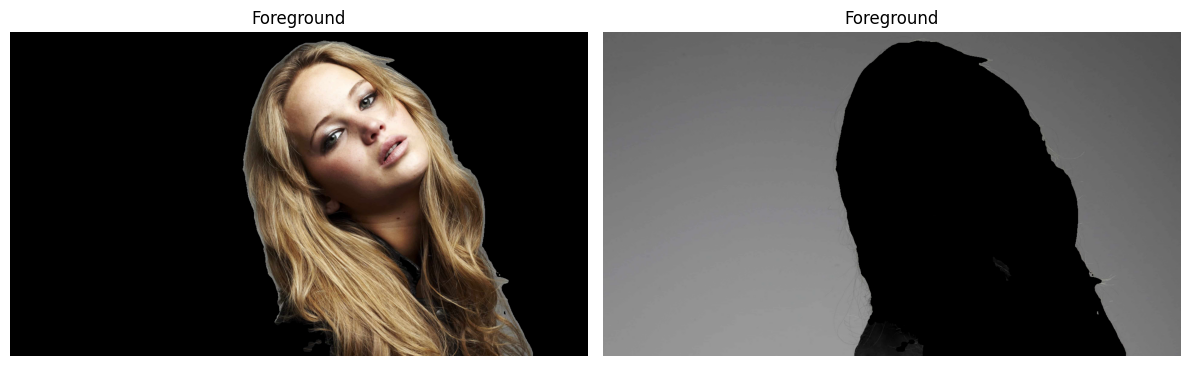

In [30]:
plt.figure(figsize=(12,6))

plt.subplot(1,2,1)
plt.imshow(foreground)
plt.title("Foreground")
plt.axis("off")
plt.subplot(1,2,2)
plt.imshow(background)
plt.title("Foreground")
plt.axis("off")

plt.tight_layout()
plt.show()

In [31]:
H,S,V = cv.split(cv.cvtColor(foreground, cv.COLOR_RGB2HSV))
norm_V = hist_equalization(V)
norm_fore = cv.cvtColor(cv.merge([H, S, norm_V]), cv.COLOR_HSV2RGB)

(0.0, 4000.0)

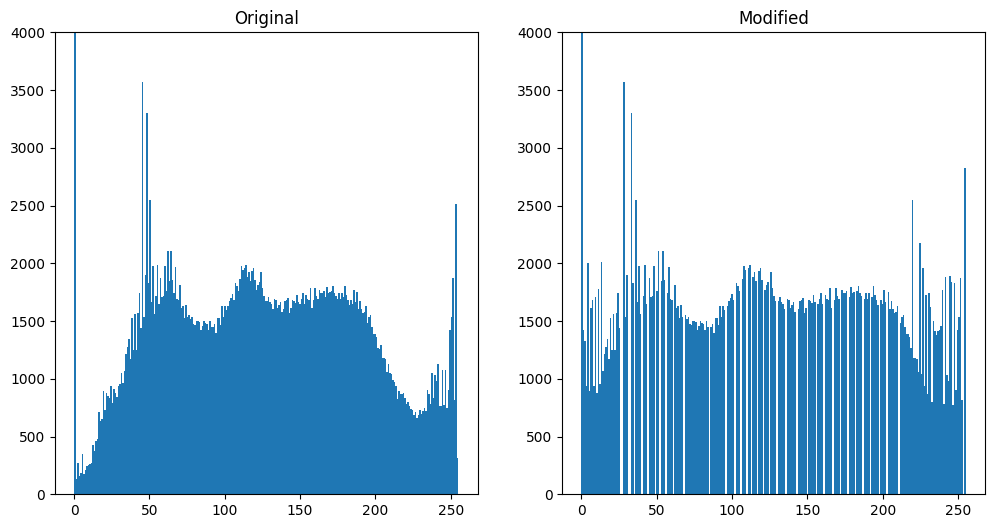

In [32]:
plt.figure(figsize=(12,6))
plt.subplot(1,2,1)
plt.hist(V.ravel(), 256, (0,255))
plt.title("Original")
plt.ylim((0, 4000))
# plt.axis("off")
plt.subplot(1,2,2)
plt.hist(norm_V.ravel(), 256, (0,255))
plt.title("Modified")
plt.ylim((0, 4000))
# plt.axis("off")

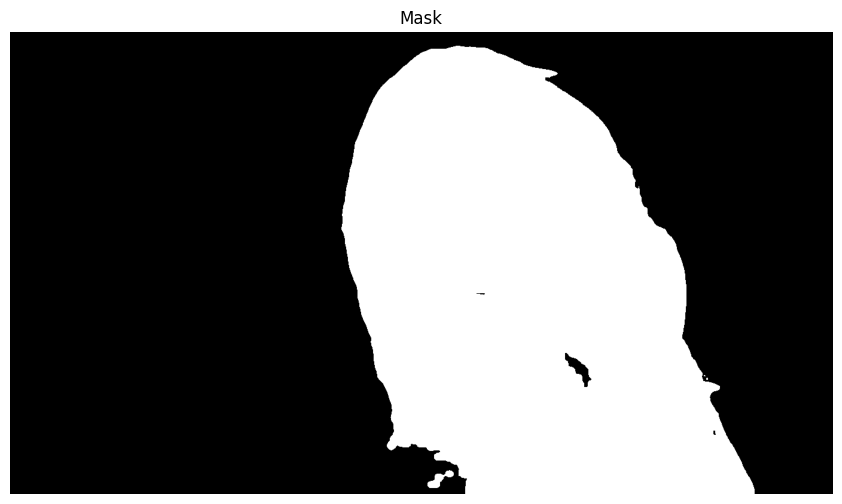

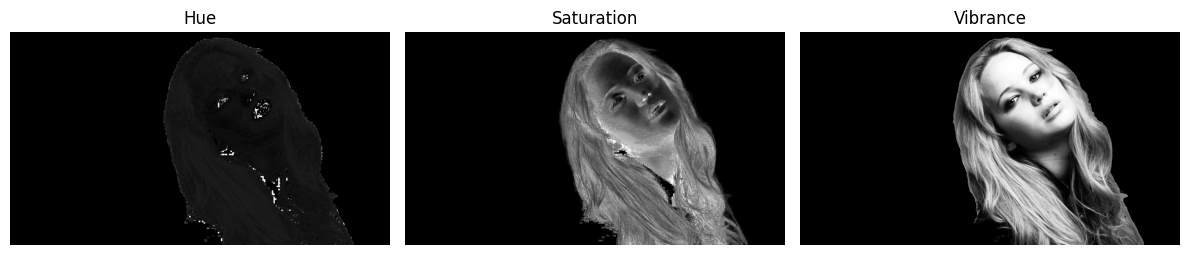

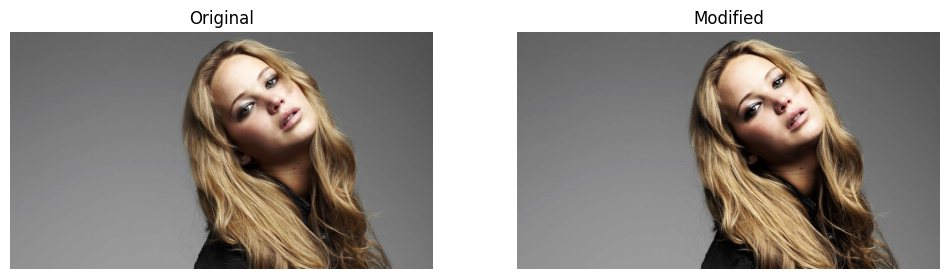

In [33]:
plt.figure(figsize=(12,6))
plt.imshow(mask, cmap="grey")
plt.title("Mask")
plt.axis("off")
plt.show()

plt.figure(figsize=(12,6))
plt.subplot(1,3,1)
plt.imshow(H, cmap="grey")
plt.title("Hue")
plt.axis("off")
plt.subplot(1,3,2)
plt.imshow(S, cmap="grey")
plt.title("Saturation")
plt.axis("off")
plt.subplot(1,3,3)
plt.imshow(norm_V, cmap="grey")
plt.title("Vibrance")
plt.axis("off")

plt.tight_layout()
plt.show()

plt.figure(figsize=(12,6))
plt.subplot(1,2,1)
plt.imshow(img)
plt.title("Original")
plt.axis("off")
plt.subplot(1,2,2)
plt.imshow(cv.add(background, norm_fore))
plt.title("Modified")
plt.axis("off")
plt.show()

# Question 7

In [34]:
img = cv.imread("Images/q7.png", cv.IMREAD_GRAYSCALE)

In [35]:
sobelX = np.array([[1,0,-1],
                   [2,0,-2],
                   [1,0,-1]])
sobelY = np.array([[1,2,1],
                   [0,0,0],
                   [-1,-2,-1]])
filteredX = cv.filter2D(img, cv.CV_32F, sobelX)
filteredY = cv.filter2D(img, cv.CV_32F, sobelY)

mag = cv.magnitude(filteredX, filteredY)

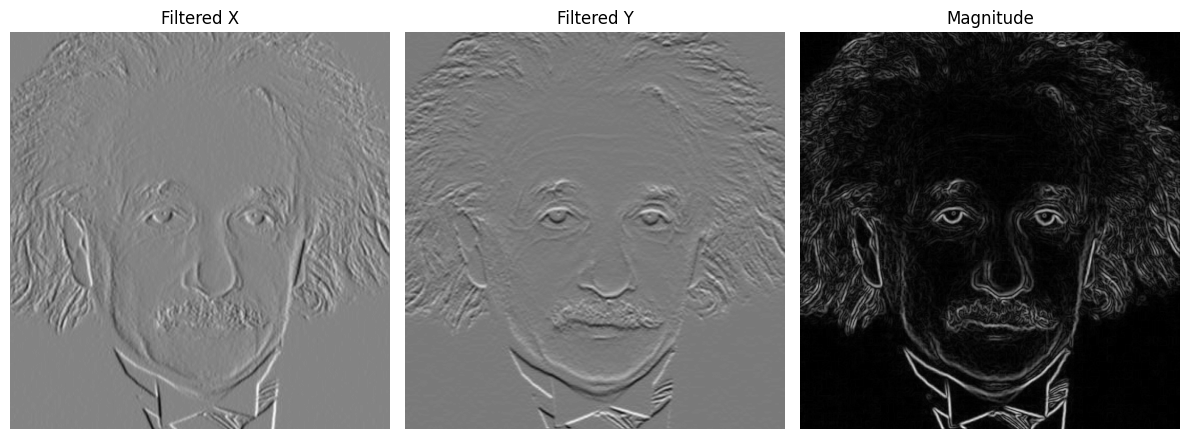

In [36]:
plt.figure(figsize=(12,6))
plt.subplot(1,3,1)
plt.imshow(filteredX, cmap="grey")
plt.title("Filtered X")
plt.axis("off")
plt.subplot(1,3,2)
plt.imshow(filteredY, cmap="grey")
plt.title("Filtered Y")
plt.axis("off")
plt.subplot(1,3,3)
plt.imshow(mag, cmap="grey")
plt.title("Magnitude")
plt.axis("off")

plt.tight_layout()
plt.show()

In [37]:
def convolve2d(img, kernel):

    h, w = img.shape
    kh, kw = kernel.shape

    ph = kh // 2
    pw = kw // 2

    padded = np.pad(
        img,
        ((ph,ph),(pw,pw)),
        mode='reflect'
    )

    output = np.zeros((h,w), dtype=np.float32)

    for y in range(h):
        for x in range(w):

            region = padded[
                y:y+kh,
                x:x+kw
            ]

            output[y,x] = np.sum(region * kernel)

    return output

In [38]:
filteredX_manual = convolve2d(img.astype(np.float32), sobelX)
filteredY_manual = convolve2d(img.astype(np.float32), sobelY)

mag_manual = np.sqrt(
    filteredX_manual**2 +
    filteredY_manual**2
)

mag_manual = cv.normalize(
    mag_manual,
    None,
    0,
    255,
    cv.NORM_MINMAX
).astype(np.uint8)

(-0.5, 804.5, 841.5, -0.5)

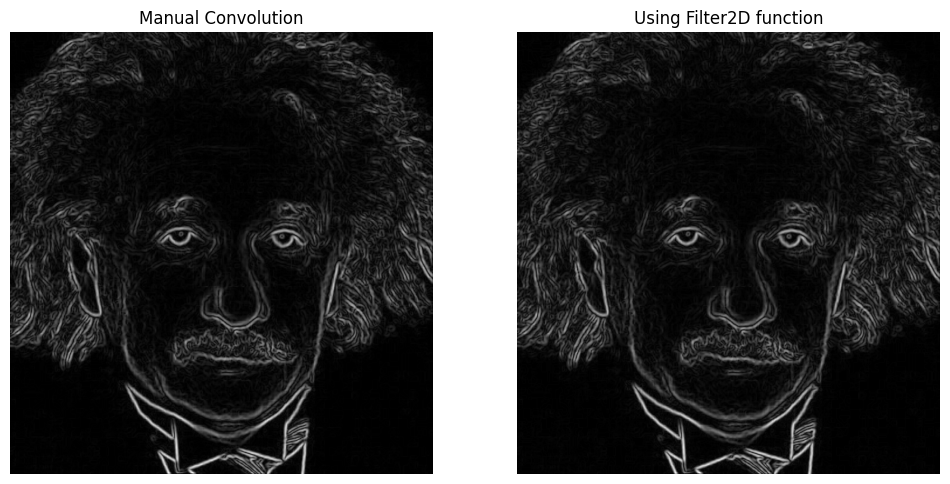

In [39]:
plt.figure(figsize=(12,6))
plt.subplot(1,2,1)
plt.imshow(mag_manual, cmap="grey")
plt.title("Manual Convolution")
plt.axis("off")
plt.subplot(1,2,2)
plt.imshow(mag, cmap="grey")
plt.title("Using Filter2D function")
plt.axis("off")

In [40]:
kX1 = np.array([[1], [2], [1]])
kX2 = np.array([[1, 0, -1]])
kY1 = np.transpose(kX2)
kY2 = np.transpose(kX1)
# kY1 = np.array([[1], [0], [-1]])
# kY2 = np.array([[1, 2, 1]])

oX1 = convolve2d(img.astype(np.float32), kX1)
X = convolve2d(oX1, kX2)
oY1 = convolve2d(img.astype(np.float32), kY1)
Y = convolve2d(oY1, kY2)

dual_manual = np.sqrt(
    X**2 +
    Y**2
)

dual_manual = cv.normalize(
    dual_manual,
    None,
    0,
    255,
    cv.NORM_MINMAX
).astype(np.uint8)

(-0.5, 804.5, 841.5, -0.5)

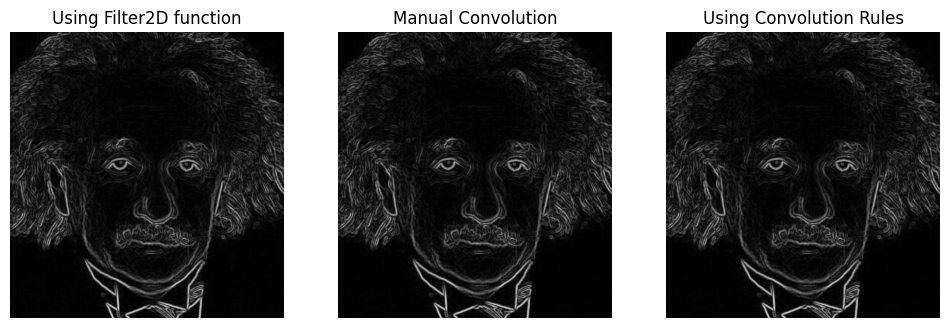

In [41]:
plt.figure(figsize=(12,6))
plt.subplot(1,3,3)
plt.imshow(dual_manual, cmap="grey")
plt.title("Using Convolution Rules")
plt.axis("off")
plt.subplot(1,3,1)
plt.imshow(mag, cmap="grey")
plt.title("Using Filter2D function")
plt.axis("off")
plt.subplot(1,3,2)
plt.imshow(mag_manual, cmap="grey")
plt.title("Manual Convolution")
plt.axis("off")